# TDE — Rede Neural aplicada a acidentes em rodovias federais

**Integrantes:** Felipe Medeiros Castello Branco · Herbeth Lucas de Sousa Pereira · Samuel Pereira da Silva Varão
**Professor:** Edilson Carlos Silva Lima
**Curso / Instituição / Semestre:** Sistema de Informação · Cest · 7° Período

Este notebook percorre o TDE completo: problema, dataset, EDA, preparação, implementação da MLP do zero em NumPy, treino, avaliação, comparação binário × 3 classes, simulador e análise crítica.

> A API FastAPI é a fonte única da verdade do projeto. O código de `NnModel` exibido abaixo é importado diretamente de `backend/nn/model.py` com `inspect.getsource`.


In [1]:
import inspect
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

# Bootstrap: funciona localmente (backend/notebooks) e no Colab com o zip do projeto.
repo_root = Path.cwd()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent.parent
backend_root = repo_root / "backend"
if str(backend_root) not in sys.path:
    sys.path.insert(0, str(backend_root))

from nn.config import CLASS_NAMES, DataConfig, ModelConfig
from nn.data import (
    build_target,
    dataset_summary,
    load_raw,
    prepare_dataset,
)
from nn.export import export_model, predict_with_json
from nn.metrics import calculate_all_metrics
from nn.model import NnModel

print("backend:", backend_root)


backend: /home/felipe-medeiros/Downloads/redes_neurais/backend


## 1. Problema e motivação

Acidentes em rodovias federais são um problema de saúde pública. A PRF registra milhares de ocorrências por ano, mas a base aberta não contém fatores decisivos para a letalidade (velocidade no impacto, cinto, tipo de veículo). O objetivo é estimar a **probabilidade de vítima fatal** a partir do cenário registrado (local, horário, via, clima, tipo de acidente etc.).

É um problema de classificação binária desbalanceada: apenas ~7,1% das ocorrências têm vítima fatal. Por isso, acurácia isolada é enganosa; usaremos F1 da classe fatal, ROC-AUC, PR-AUC, log-loss, Brier e calibração.


## 2. Dataset oficial

**Fonte:** Polícia Rodoviária Federal (PRF) — DATATRAN 2024, visão "agrupada por ocorrência".
**Granularidade:** 1 linha = 1 acidente. **Variável-alvo:** `classificacao_acidente` / `mortos`.

| Item | Valor |
|---|---|
| Registros no arquivo | 73.202 |
| Registros usados | 73.201 (1 linha com alvo `NA`) |
| Colunas | 30 |
| Encoding | latin-1, separador `;`, decimal com vírgula |
| Vítimas fatais | 5.225 (7,1%) |


In [2]:
raw = load_raw()
print(f"Shape: {raw.shape}")
print("Alvo:")
display(raw["classificacao_acidente"].value_counts().to_frame("ocorrências"))

info = pd.DataFrame(
    {
        "dtype": raw.dtypes.astype(str),
        "nulos": raw.isna().sum(),
        "únicos": raw.nunique(),
    }
)
display(info)


Shape: (73201, 30)
Alvo:


,ocorrências
classificacao_acidente,
Com Vítimas Feridas,56194
Sem Vítimas,11782
Com Vítimas Fatais,5225


,dtype,nulos,únicos
id,float64,0,73201
data_inversa,str,0,366
dia_semana,str,0,7
horario,str,0,1414
uf,str,0,27
br,Int64,0,113
km,float64,0,7685
municipio,str,0,1834
causa_acidente,str,0,69
tipo_acidente,str,0,17


## 3. Análise exploratória (EDA)

A classe "Com Vítimas Feridas" domina a base. O desbalanceamento justifica pesos de classe e métricas além da acurácia.


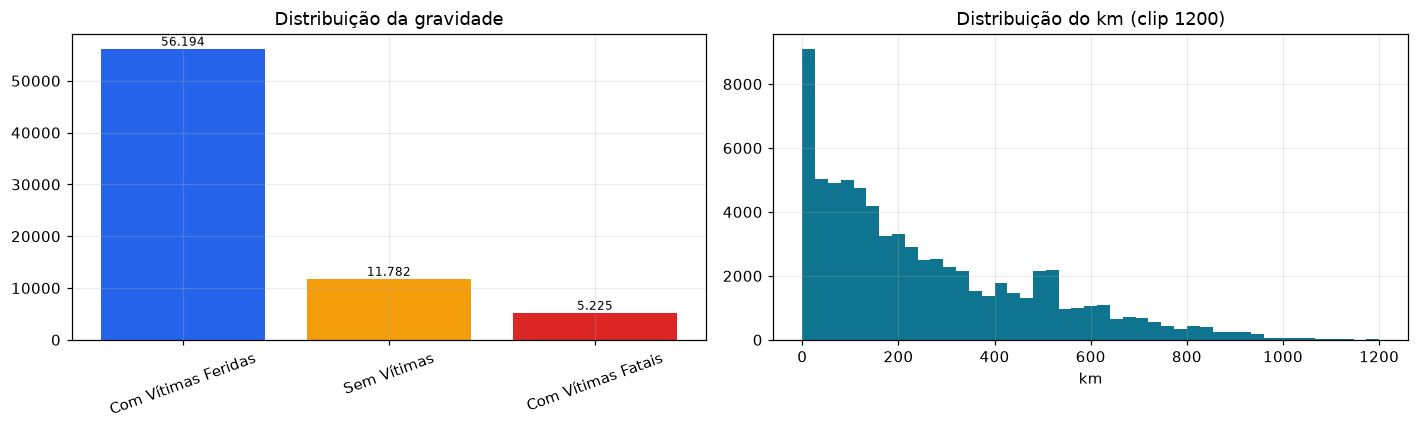

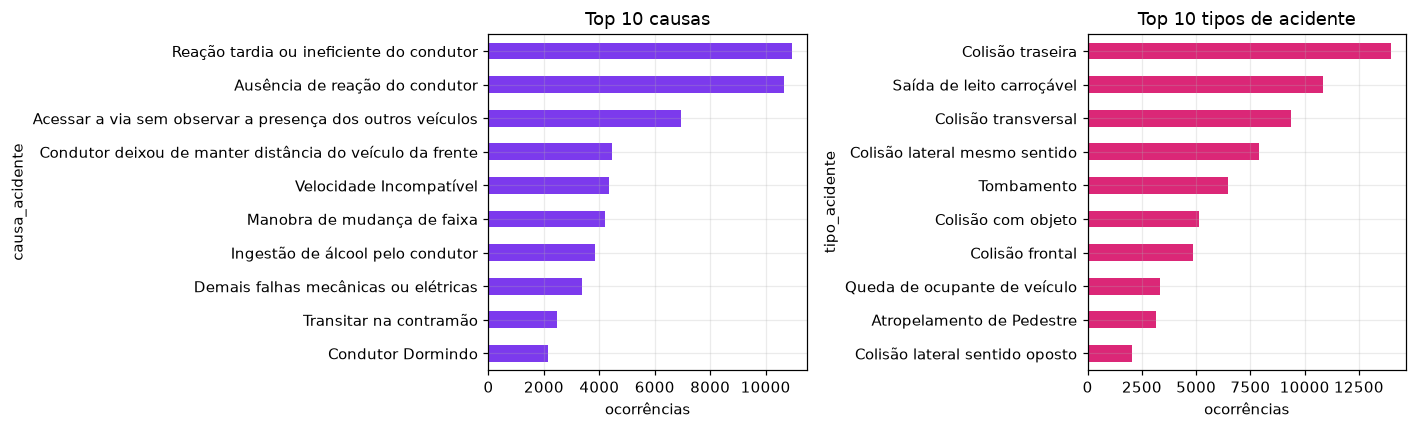

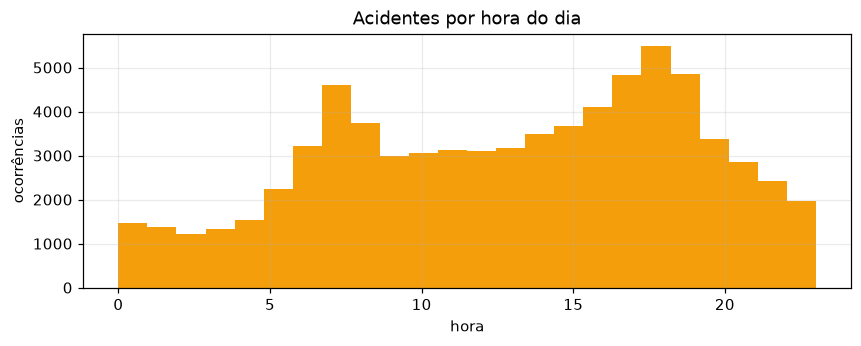

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

counts = raw["classificacao_acidente"].value_counts()
axes[0].bar(counts.index, counts.values, color=["#2563eb", "#f59e0b", "#dc2626"])
axes[0].set_title("Distribuição da gravidade")
axes[0].tick_params(axis="x", rotation=20)
for i, value in enumerate(counts.values):
    axes[0].text(i, value, f"{value:,}".replace(",", "."), ha="center", va="bottom", fontsize=8)

raw["km"].clip(upper=1200).hist(bins=45, ax=axes[1], color="#0e7490")
axes[1].set_title("Distribuição do km (clip 1200)")
axes[1].set_xlabel("km")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
raw["causa_acidente"].value_counts().head(10).sort_values().plot(
    kind="barh", ax=axes[0], color="#7c3aed"
)
axes[0].set_title("Top 10 causas")
axes[0].set_xlabel("ocorrências")

raw["tipo_acidente"].value_counts().head(10).sort_values().plot(
    kind="barh", ax=axes[1], color="#db2777"
)
axes[1].set_title("Top 10 tipos de acidente")
axes[1].set_xlabel("ocorrências")
plt.tight_layout()
plt.show()

hour = pd.to_datetime(raw["horario"], format="%H:%M:%S", errors="coerce").dt.hour
hour.hist(bins=24, figsize=(9, 3), color="#f59e0b")
plt.title("Acidentes por hora do dia")
plt.xlabel("hora")
plt.ylabel("ocorrências")
plt.show()


## 4. Preparação, features e split

- Features numéricas: `br`, `km`, `veiculos`, `hora_sin`, `hora_cos`, `is_fim_semana`.
- Categóricas: UF, dia, via, clima, causa, tipo etc., com one-hot e agrupamento de categorias raras em `__OUTROS__`.
- Split estratificado 60/20/20, fit do preprocessor **somente no treino**.
- Pesos de classe balanceados.


In [4]:
cfg = DataConfig(target="fatal_binario", max_rows=8000, seed=42)
dataset = prepare_dataset(cfg)
summary = dataset_summary(dataset)
print(json.dumps(summary, indent=2, ensure_ascii=False))
print("\nPrimeiras features:", dataset.feature_names[:12])
print("Pesos de classe:", np.round(dataset.class_weights, 4))


{
  "target": "fatal_binario",
  "class_names": [
    "sem_vitima_fatal",
    "vitima_fatal"
  ],
  "raw_rows": 73201,
  "used_rows": 8000,
  "split_sizes": {
    "train": 4800,
    "val": 1600,
    "test": 1600
  },
  "class_counts": {
    "all": [
      7429,
      571
    ],
    "train": [
      4457,
      343
    ],
    "val": [
      1486,
      114
    ],
    "test": [
      1486,
      114
    ]
  },
  "class_weights": [
    0.5384787973973525,
    6.997084548104956
  ],
  "n_features": 110,
  "n_numeric_features": 6,
  "n_categorical_columns": 10,
  "feature_schema_hash": "a372163e2a4c565e",
  "scaler": "standard",
  "log1p_numeric": true,
  "rare_min_count": 30,
  "max_rows": 8000
}

Primeiras features: ('br', 'km', 'hora_sin', 'hora_cos', 'is_fim_semana', 'veiculos', 'uf=AL', 'uf=BA', 'uf=CE', 'uf=DF', 'uf=ES', 'uf=GO')
Pesos de classe: [0.5385 6.9971]


## 5. O núcleo: `NnModel` implementado do zero

A célula abaixo imprime o código-fonte real da classe usada pela API. Ela contém `__init__`, `forward`, `loss`, `backward`, `step` e `fit`, com softmax estável, dropout inverted, L2, gradient clipping, Adam/AdamW e early stopping.


In [5]:
print(inspect.getsource(NnModel))


class NnModel:
    """Rede Neural Multi-Layer Perceptron (MLP) totalmente em NumPy.

    Implementa forward pass com cache, derivadas analíticas em forma fechada,
    inverted dropout, L2 regularization, gradient clipping por norma global,
    e otimizadores SGD, Momentum, Adam e AdamW.
    """

    def __init__(
        self,
        n_inputs: int,
        n_outputs: int,
        cfg: ModelConfig | None = None,
        class_weights: np.ndarray | None = None,
    ) -> None:
        self.n_inputs = n_inputs
        self.n_outputs = n_outputs
        self.cfg = cfg if cfg is not None else ModelConfig()

        if class_weights is not None:
            weights_arr = np.asarray(class_weights, dtype=np.float64)
            if weights_arr.shape != (n_outputs,):
                raise ValueError(
                    f"class_weights deve ter formato ({n_outputs},); recebido {weights_arr.shape}"
                )
            self.class_weights = weights_arr
        else:
            self.class

## 6. Arquitetura e hiperparâmetros

Rede pequena e interpretável para o TDE: **entrada (features) → 1 camada oculta ReLU (32) → softmax (2 saídas)**. `weighted_ce` compensa o desbalanceamento; Adam com `lr=1e-3`; early stopping na `loss_val`.


In [6]:
model_cfg = ModelConfig(
    hidden_layers=1,
    neurons=(32,),
    activation="relu",
    init="he",
    dropout=0.0,
    l2=0.0,
    loss="weighted_ce",
    optimizer="adam",
    lr=1e-3,
    batch_size=256,
    epochs=40,
    patience=8,
    grad_clip=5.0,
    threshold=0.5,
    seed=42,
)

model = NnModel(
    n_inputs=dataset.input_dim,
    n_outputs=dataset.n_classes,
    cfg=model_cfg,
    class_weights=dataset.class_weights,
)
n_params = sum(w.size + b.size for w, b in zip(model.weights, model.biases, strict=True))
print(f"Entrada: {dataset.input_dim} | camadas: {[w.shape for w in model.weights]}")
print(f"Parâmetros treináveis: {n_params:,}".replace(",", "."))


Entrada: 110 | camadas: [(110, 32), (32, 2)]
Parâmetros treináveis: 3.618


## 7. Treinamento e evolução das curvas

O log imprime aproximadamente 10% das épocas. O early stopping restaura o melhor checkpoint de validação.


época 004/40 loss=0.5897 val=0.6051 f1_val=0.5392
época 008/40 loss=0.5166 val=0.5540 f1_val=0.5813


época 012/40 loss=0.4675 val=0.5373 f1_val=0.5943


época 016/40 loss=0.4341 val=0.5390 f1_val=0.6015
época 020/40 loss=0.4078 val=0.5425 f1_val=0.5977


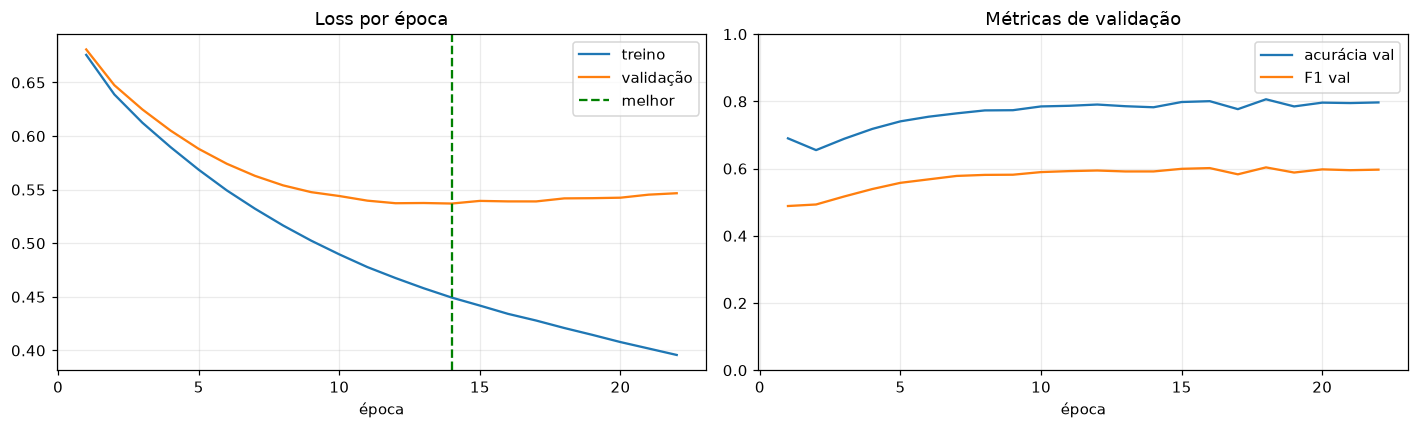

Melhor época: 14 | early stopping: True
Tempo: 0.4s


In [7]:
log_every = max(1, model_cfg.epochs // 10)

def log_epoch(event):
    if event["epoch"] % log_every == 0 or event["epoch"] == event["epochs"]:
        print(
            f"época {event['epoch']:03d}/{event['epochs']} "
            f"loss={event['loss_train']:.4f} val={event['loss_val']:.4f} "
            f"f1_val={event['f1_val']:.4f}"
        )

history = model.fit(
    dataset.X_train,
    dataset.y_train,
    dataset.X_val,
    dataset.y_val,
    on_epoch=log_epoch,
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history.epochs, history.loss_train, label="treino")
axes[0].plot(history.epochs, history.loss_val, label="validação")
axes[0].axvline(history.best_epoch, color="green", ls="--", label="melhor")
axes[0].set_title("Loss por época")
axes[0].set_xlabel("época")
axes[0].legend()

axes[1].plot(history.epochs, history.acc_val, label="acurácia val")
axes[1].plot(history.epochs, history.f1_val, label="F1 val")
axes[1].set_ylim(0, 1)
axes[1].set_title("Métricas de validação")
axes[1].set_xlabel("época")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Melhor época: {history.best_epoch} | early stopping: {history.stopped_early}")
print(f"Tempo: {history.seconds[-1]:.1f}s")


## 8. Avaliação no conjunto de teste

O teste é usado **uma única vez**, com o melhor checkpoint. Avaliamos matriz de confusão, P/R/F1 por classe, ROC-AUC, PR-AUC, log-loss, Brier, calibração e varredura de limiar.


In [8]:
probs = model.predict_proba(dataset.X_test)
preds = model.predict(dataset.X_test)
metrics = calculate_all_metrics(
    dataset.y_test, probs, threshold=model_cfg.threshold, n_classes=dataset.n_classes
)

print(f"Acurácia: {metrics['accuracy']:.4f}")
print(f"F1 macro: {metrics['precision_recall_f1']['macro']['f1']:.4f}")
print(f"F1 weighted: {metrics['precision_recall_f1']['weighted']['f1']:.4f}")
print(f"ROC-AUC: {metrics['roc_auc']:.4f}")
print(f"PR-AUC: {metrics['pr_auc']:.4f}")
print(f"Log-loss: {metrics['log_loss']:.4f} | Brier: {metrics['brier_score']:.4f} | ECE: {metrics['ece']:.4f}")

display(pd.DataFrame(metrics["precision_recall_f1"]["per_class"]))


Acurácia: 0.7788
F1 macro: 0.5910
F1 weighted: 0.8286
ROC-AUC: 0.8001
PR-AUC: 0.2989
Log-loss: 0.5035 | Brier: 0.3297 | ECE: 0.0552


,class_index,precision,recall,f1,support
0,0,0.972454,0.783984,0.868107,1486
1,1,0.201493,0.710526,0.313953,114


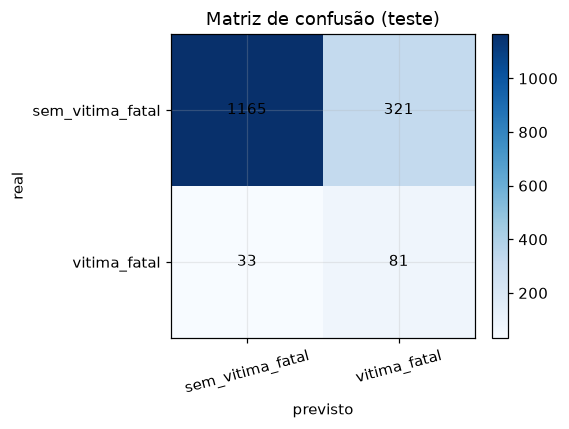

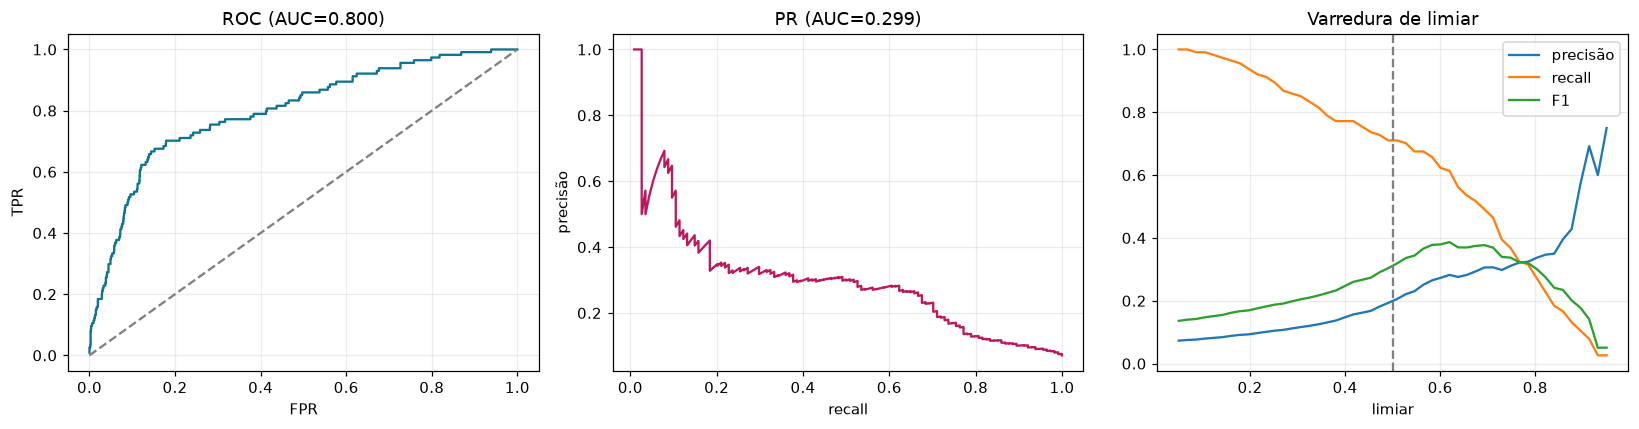

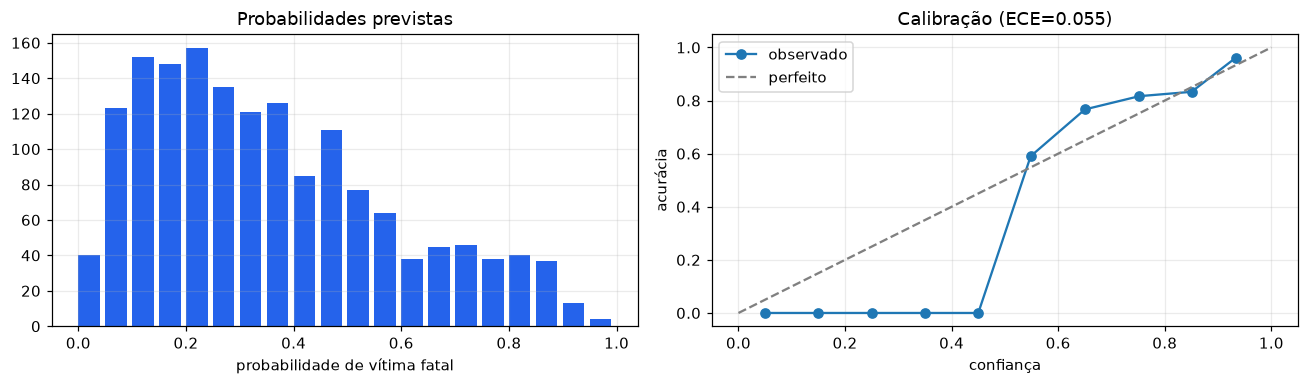

In [9]:
class_names = list(CLASS_NAMES[cfg.target])
cm = np.asarray(metrics["confusion_matrix"])

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(class_names)))
ax.set_yticks(range(len(class_names)))
ax.set_xticklabels(class_names, rotation=15)
ax.set_yticklabels(class_names)
ax.set_xlabel("previsto")
ax.set_ylabel("real")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="black")
ax.set_title("Matriz de confusão (teste)")
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

score = probs[:, 1]
order = np.argsort(-score)
y_sorted = dataset.y_test[order]
tpr = np.cumsum(y_sorted) / y_sorted.sum()
fpr = np.cumsum(1 - y_sorted) / (len(y_sorted) - y_sorted.sum())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(fpr, tpr, color="#0e7490")
axes[0].plot([0, 1], [0, 1], ls="--", color="gray")
axes[0].set_title(f"ROC (AUC={metrics['roc_auc']:.3f})")
axes[0].set_xlabel("FPR")
axes[0].set_ylabel("TPR")

precision = np.cumsum(y_sorted) / np.arange(1, len(y_sorted) + 1)
recall = np.cumsum(y_sorted) / y_sorted.sum()
axes[1].plot(recall, precision, color="#be185d")
axes[1].set_title(f"PR (AUC={metrics['pr_auc']:.3f})")
axes[1].set_xlabel("recall")
axes[1].set_ylabel("precisão")

sweep = pd.DataFrame(metrics["threshold_sweep"])
axes[2].plot(sweep["threshold"], sweep["precision"], label="precisão")
axes[2].plot(sweep["threshold"], sweep["recall"], label="recall")
axes[2].plot(sweep["threshold"], sweep["f1"], label="F1")
axes[2].axvline(model_cfg.threshold, ls="--", color="gray")
axes[2].set_title("Varredura de limiar")
axes[2].set_xlabel("limiar")
axes[2].legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
hist = metrics["prediction_histogram"]
axes[0].bar(hist["bin_edges"][:-1], hist["counts"], width=0.04, align="edge", color="#2563eb")
axes[0].set_title("Probabilidades previstas")
axes[0].set_xlabel("probabilidade de vítima fatal")

calib = pd.DataFrame(metrics["calibration_bins"])
axes[1].plot(calib["confidence"], calib["accuracy"], marker="o", label="observado")
axes[1].plot([0, 1], [0, 1], ls="--", color="gray", label="perfeito")
axes[1].set_title(f"Calibração (ECE={metrics['ece']:.3f})")
axes[1].set_xlabel("confiança")
axes[1].set_ylabel("acurácia")
axes[1].legend()
plt.tight_layout()
plt.show()


## 9. Baseline majoritário e o perigo da acurácia

Um classificador que sempre prevê "sem vítima fatal" já acerta ~93% dos casos, mas tem recall zero para a classe de interesse. O F1 macro e o PR-AUC expõem esse comportamento.


In [10]:
baseline = np.bincount(dataset.y_test).max() / len(dataset.y_test)
fatal_f1 = metrics["precision_recall_f1"]["per_class"][1]["f1"]
print(f"Baseline majoritário (acurácia): {baseline:.4f}")
print(f"Modelo (acurácia):              {metrics['accuracy']:.4f}")
print(f"Modelo (F1 da classe fatal):    {fatal_f1:.4f}")
print(f"Modelo (F1 macro):              {metrics['precision_recall_f1']['macro']['f1']:.4f}")


Baseline majoritário (acurácia): 0.9287
Modelo (acurácia):              0.7788
Modelo (F1 da classe fatal):    0.3140
Modelo (F1 macro):              0.5910


## 9.1 Comparativo binário × 3 classes

A mesma arquitetura é treinada para o alvo de 3 classes (Sem Vítimas, Com Feridos, Com Fatais). O objetivo é mostrar que a formulação multiclasse é mais difícil e que o binário é mais adequado para triagem de letalidade.


In [11]:
cfg3 = DataConfig(target="gravidade_3_classes", max_rows=8000, seed=42)
dataset3 = prepare_dataset(cfg3)
model_cfg3 = ModelConfig(
    hidden_layers=1, neurons=(32,), activation="relu", init="he",
    loss="weighted_ce", optimizer="adam", lr=1e-3, batch_size=256,
    epochs=30, patience=8, threshold=0.5, seed=42,
)
model3 = NnModel(
    n_inputs=dataset3.input_dim,
    n_outputs=dataset3.n_classes,
    cfg=model_cfg3,
    class_weights=dataset3.class_weights,
)
history3 = model3.fit(dataset3.X_train, dataset3.y_train, dataset3.X_val, dataset3.y_val)
probs3 = model3.predict_proba(dataset3.X_test)
metrics3 = calculate_all_metrics(
    dataset3.y_test, probs3, threshold=model_cfg3.threshold, n_classes=dataset3.n_classes
)

comparison = pd.DataFrame(
    {
        "binário": [
            metrics["accuracy"],
            metrics["precision_recall_f1"]["macro"]["f1"],
            metrics["roc_auc"],
            metrics["pr_auc"],
            metrics["log_loss"],
        ],
        "3 classes": [
            metrics3["accuracy"],
            metrics3["precision_recall_f1"]["macro"]["f1"],
            metrics3["roc_auc"],
            metrics3["pr_auc"],
            metrics3["log_loss"],
        ],
    },
    index=["acurácia", "F1 macro", "ROC-AUC", "PR-AUC", "log-loss"],
)
display(comparison.round(4))


,binário,3 classes
acurácia,0.7788,0.5931
F1 macro,0.5910,0.4817
ROC-AUC,0.8001,0.7494
PR-AUC,0.2989,0.5385
log-loss,0.5035,0.8857


## 10. Simulador com um caso exemplo

O simulador da API usa exatamente `predict_with_json`: recebe a linha bruta, aplica o preprocessor exportado e executa o forward pass. Aqui mostramos o mesmo caminho com um acidente real do dataset.


In [12]:
export_payload = export_model(model, dataset.preprocessor, model_cfg, cfg, metrics)
sample = raw.iloc[0].to_dict()
prediction = predict_with_json(export_payload, sample)
print(json.dumps(prediction, indent=2, ensure_ascii=False))


{
  "predicted_class_index": 1,
  "predicted_class": "vitima_fatal",
  "probabilities": {
    "sem_vitima_fatal": 0.4471,
    "vitima_fatal": 0.5529
  },
  "threshold_used": 0.5,
  "contributions": [
    {
      "feature": "uso_solo",
      "delta": -0.7015769148393757
    },
    {
      "feature": "condicao_metereologica",
      "delta": 0.40281879246958163
    },
    {
      "feature": "dia_semana",
      "delta": -0.3939749404893135
    },
    {
      "feature": "tipo_acidente",
      "delta": 0.3655479425190947
    },
    {
      "feature": "causa_acidente",
      "delta": -0.3447008238631637
    },
    {
      "feature": "br",
      "delta": 0.2297567728949291
    }
  ]
}


## 11. Exportação e reprodutibilidade

- Seeds fixas (`42`) em dados, split e inicialização.
- Preprocessor serializável em JSON com hash de schema.
- `model.json` autocontido para o simulador e `weights.npz` para inspeção.
- Compose sobe `data`, `db`, `api` e `web` com um comando.

Comandos de reprodução:

```bash
make fetch
make up
make seed
```


In [13]:
import hashlib

csv_path = backend_root / "data" / "raw" / "datatran2024.csv"
sha = hashlib.sha256(csv_path.read_bytes()).hexdigest()
print("SHA-256 do CSV:", sha)
print("Schema hash:", dataset.preprocessor.schema_hash)
print("Seed:", cfg.seed)
print("Alvo:", cfg.target)
print("Split:", dataset.splits.sizes)


SHA-256 do CSV: 7d26e6f4528c2ca2636a8fea2c5bc8755a0ff6a182d82c238a8793b016e4366d
Schema hash: a372163e2a4c565e
Seed: 42
Alvo: fatal_binario
Split: {'train': 4800, 'val': 1600, 'test': 1600}


## 12. Análise crítica, limitações e melhorias

### O que o modelo aprendeu
A rede captura padrões plausíveis de gravidade a partir de tipo de acidente, via, clima, horário e localização. O F1 da classe fatal e o PR-AUC são mais informativos que a acurácia.

### Limitações
1. **Fatores ausentes:** velocidade, cinto, tipo de veículo, tempo de socorro e condições do condutor não estão na base.
2. **Subnotificação e qualidade:** o preenchimento varia por unidade da PRF.
3. **Causa provável:** `causa_acidente` é atribuição do boletim, não medição.
4. **Recorte de 2024:** não generaliza automaticamente para outros anos.
5. **Granularidade por ocorrência:** perde detalhes por pessoa.

### Melhorias
- Engenharia de features com interações (tipo de acidente × via × clima).
- Calibração de probabilidades (Platt/isotônica).
- Comparação com gradient boosting e regressão logística como baselines.
- Validação temporal e por UF.
- Explicabilidade local (SHAP/permutação) e análise de subgrupos.

### Conclusão
A MLP implementada do zero em NumPy é viável e didática. O teto de desempenho é limitado pela base, não pela arquitetura; o projeto entrega uma aplicação reproduzível com API, banco, frontend e simulador.
